## Importing libraries

In [1]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
import os


## Loading datasets

In [2]:
(train_images, train_labels), (test_images, test_labels) = tf.keras.datasets.cifar10.load_data()


170508288/170498071 [==============================] - 2s 0us/step


## Data normalization

In [3]:

train_images = train_images / 255.0
test_images = test_images / 255.0

In [4]:
train_images.shape,test_images.shape

((50000, 32, 32, 3), (10000, 32, 32, 3))

In [5]:
train_labels = tf.keras.utils.to_categorical(train_labels)
test_labels = tf.keras.utils.to_categorical(test_labels)


In [7]:
train_images.shape,test_images.shape

((50000, 32, 32, 3), (10000, 32, 32, 3))

In [8]:
label_names = {    
0 : 'airplane',										
1 : 'automobile',										
2 : 'bird',										
3 : 'cat',										
4 : 'deer',										
5 : 'dog',										
6 : 'frog',
7 : 'horse',										
8 : 'ship',										
9 : 'truck',
}


## plotting images

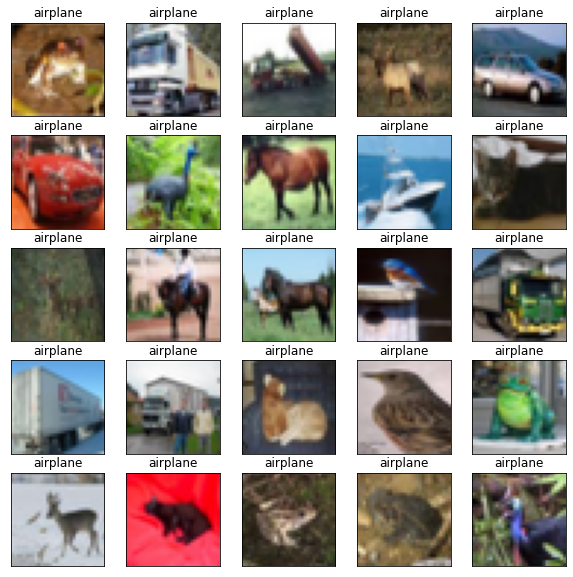

In [9]:
rows, columns = 5, 5
fig = plt.figure(figsize=(10,10))
for i in range(1,columns*rows+1):
  fig.add_subplot(rows, columns, i)
  plt.imshow(train_images[i-1])
  plt.xticks([])
  plt.yticks([])
  plt.title("{}".format(label_names[train_labels[i-1][0]]))
plt.show();

## Callbacks

In [10]:
filepath = '/content/drive/MyDrive/Colab Notebooks/week7.h5'
checkpoint = tf.keras.callbacks.ModelCheckpoint(filepath,monitor = 'val_loss', verbose = 1, save_best_only = True, mode = 'min')

stop_early = tf.keras.callbacks.EarlyStopping(monitor ='val_accuracy',mode = 'auto', patience = 5)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',factor = 0.2, patience = 5,mode = 'auto', min_lr = 0.0001)
callbacklist = [stop_early,reduce_lr,checkpoint]


In [11]:
from tensorflow.keras.regularizers import l1,l2
weight_decay = 1e-4
batch_size = 64
initial_epochs = 10
lr = 0.001
lr_decay = 1e-6
def model_build():
  inputs = keras.Input(shape=(32, 32, 3))
  x = tf.keras.layers.Conv2D(filters = 32,
                             kernel_size = (3,3),
                             padding = 'same', 
                             activation = 'relu', 
                             kernel_regularizer = l2(weight_decay)
                             )(inputs)
  x = tf.keras.layers.BatchNormalization()(x)

  x = tf.keras.layers.MaxPool2D(pool_size=(2,2))(x)
  x = tf.keras.layers.Dropout(rate = 0.2)(x)
  
  x = tf.keras.layers.Conv2D(filters = 64,
                             kernel_size = (3,3),
                             padding = 'same',
                             activation = 'relu',
                             kernel_regularizer = l2(weight_decay)
                             )(x)
  x = tf.keras.layers.BatchNormalization()(x)

  
  x = tf.keras.layers.MaxPool2D(pool_size=(2,2))(x)

  x = tf.keras.layers.Dropout(rate = 0.3)(x)
  
  x = tf.keras.layers.Conv2D(filters = 128,
                             kernel_size = (3,3),
                             padding = 'same',
                             activation = 'relu',
                             kernel_regularizer =  l2(weight_decay)
                             )(x)
  x = tf.keras.layers.BatchNormalization()(x)
  
  
  x = tf.keras.layers.MaxPool2D(pool_size=(2,2))(x)
  
  x = tf.keras.layers.Dropout(rate = 0.4)(x)
  
  x = tf.keras.layers.Flatten()(x)
  
  x = tf.keras.layers.Dense(1024, activation = 'relu')(x)
  x = tf.keras.layers.Dropout(rate = 0.3)(x)

  x = tf.keras.layers.Dense(256, activation = 'relu')(x)
  x = tf.keras.layers.Dropout(rate = 0.2)(x)
  
  outputs = tf.keras.layers.Dense(10, activation = 'softmax')(x)
  model = tf.keras.Model(inputs = inputs,outputs=outputs, name ='cifar-10')

  model.compile(loss = tf.keras.losses.CategoricalCrossentropy(),
                optimizer = tf.keras.optimizers.Adam(learning_rate= lr, decay = lr_decay),
                metrics=['accuracy'])
  return model

In [12]:
my_model = model_build()
my_model.summary()

Model: "cifar-10"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 32, 32, 3)]       0         
                                                                 
 conv2d (Conv2D)             (None, 32, 32, 32)        896       
                                                                 
 batch_normalization (BatchN  (None, 32, 32, 32)       128       
 ormalization)                                                   
                                                                 
 max_pooling2d (MaxPooling2D  (None, 16, 16, 32)       0         
 )                                                               
                                                                 
 dropout (Dropout)           (None, 16, 16, 32)        0         
                                                                 
 conv2d_1 (Conv2D)           (None, 16, 16, 64)        184

In [13]:
epochs = 10
batch_size = 64
h1 = my_model.fit(train_images, 
                 train_labels, 
                 validation_split=0.2, 
                 epochs=epochs, 

                 callbacks = callbacklist)

Epoch 1/10
1250/1250 [==============================] - ETA: 0s - loss: 1.6592 - accuracy: 0.4160
Epoch 1: val_loss improved from inf to 1.27934, saving model to /content/drive/MyDrive/Colab Notebooks/week7.h5
1250/1250 [==============================] - 31s 17ms/step - loss: 1.6592 - accuracy: 0.4160 - val_loss: 1.2793 - val_accuracy: 0.5526 - lr: 0.0010
Epoch 2/10
1250/1250 [==============================] - ETA: 0s - loss: 1.2943 - accuracy: 0.5482
Epoch 2: val_loss did not improve from 1.27934
1250/1250 [==============================] - 21s 17ms/step - loss: 1.2943 - accuracy: 0.5482 - val_loss: 1.4340 - val_accuracy: 0.5060 - lr: 0.0010
Epoch 3/10
1248/1250 [============================>.] - ETA: 0s - loss: 1.1400 - accuracy: 0.6090
Epoch 3: val_loss improved from 1.27934 to 1.10018, saving model to /content/drive/MyDrive/Colab Notebooks/week7.h5
1250/1250 [==============================] - 21s 17ms/step - loss: 1.1400 - accuracy: 0.6089 - val_loss: 1.1002 - val_accuracy: 0.6242 

In [14]:
total_epochs = epochs + 30
h2 = my_model.fit(train_images,train_labels,
                     validation_split = 0.2,
                     initial_epoch = h1.epoch[-1],
                     epochs = total_epochs,                     
                     callbacks = callbacklist)

Epoch 10/40
1249/1250 [============================>.] - ETA: 0s - loss: 0.7763 - accuracy: 0.7571
Epoch 10: val_loss did not improve from 0.79528
1250/1250 [==============================] - 19s 15ms/step - loss: 0.7763 - accuracy: 0.7571 - val_loss: 0.8108 - val_accuracy: 0.7454 - lr: 0.0010
Epoch 11/40
1248/1250 [============================>.] - ETA: 0s - loss: 0.7612 - accuracy: 0.7648
Epoch 11: val_loss improved from 0.79528 to 0.76773, saving model to /content/drive/MyDrive/Colab Notebooks/week7.h5
1250/1250 [==============================] - 19s 15ms/step - loss: 0.7608 - accuracy: 0.7649 - val_loss: 0.7677 - val_accuracy: 0.7719 - lr: 0.0010
Epoch 12/40
1248/1250 [============================>.] - ETA: 0s - loss: 0.7361 - accuracy: 0.7740
Epoch 12: val_loss did not improve from 0.76773
1250/1250 [==============================] - 19s 15ms/step - loss: 0.7362 - accuracy: 0.7739 - val_loss: 0.7872 - val_accuracy: 0.7664 - lr: 0.0010
Epoch 13/40
1248/1250 [=======================

## Performance

### Accuracy

<built-in method keys of dict object at 0x7fe1c02af820>


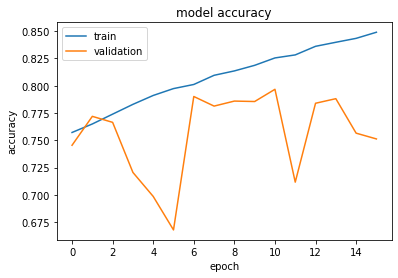

In [15]:
print(h2.history.keys)
plt.plot(h2.history['accuracy'])
plt.plot(h2.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()


### Loss

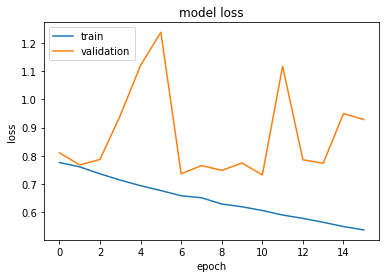

In [16]:

plt.plot(h2.history['loss'])
plt.plot(h2.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

## Evaluation

In [17]:
test_loss, test_acc = my_model.evaluate(test_images, test_labels)
print('\nTest accuracy: {}'.format(test_acc))

313/313 [==============================] - 2s 6ms/step - loss: 0.9604 - accuracy: 0.7444

Test accuracy: 0.7444000244140625


## Model Deployment

In [ ]:
from flask import Flask,request
from tensorflow.keras.models import Model
from tensorflow.keras.models import Model,Sequential,load_model
import pickle
import numpy as np
from tensorflow.keras.preprocessing import load_img